In [4]:

from google.colab import drive

drive.mount("/content/drive")


Mounted at /content/drive


In [8]:

from pathlib import Path
import gc
import json
import warnings

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import sklearn
import xgboost as xgb
import joblib

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")

TRAIN_PATH = PROJECT_ROOT / "data/splits/train.parquet"
VALIDATION_PATH = PROJECT_ROOT / "data/splits/validation.parquet"
TEST_PATH = PROJECT_ROOT / "data/splits/test.parquet"

MODEL_DIR = PROJECT_ROOT / "models/binary"
METRICS_DIR = PROJECT_ROOT / "outputs/metrics"
FIGURES_DIR = PROJECT_ROOT / "outputs/figures"
PREDICTIONS_DIR = PROJECT_ROOT / "outputs/predictions"

for directory in [
    MODEL_DIR,
    METRICS_DIR,
    FIGURES_DIR,
    PREDICTIONS_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

for path in [TRAIN_PATH, VALIDATION_PATH, TEST_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Missing dataset: {path}")

print("Project root:", PROJECT_ROOT)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgb.__version__)
print("Joblib:", joblib.__version__)
print("\nAll split files found.")


Project root: /content/drive/MyDrive/H-IDS
NumPy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1
XGBoost: 3.4.1
Joblib: 1.6.0

All split files found.


In [9]:

for name, path in [
    ("TRAIN", TRAIN_PATH),
    ("VALIDATION", VALIDATION_PATH),
    ("TEST", TEST_PATH),
]:
    schema = pq.read_schema(path)
    print(f"\n{name}")
    print("Rows:", f"{pq.ParquetFile(path).metadata.num_rows:,}")
    print("Columns:", schema.names)

    if "label" not in schema.names:
        raise ValueError(f"'label' column missing in {name}.")
    if "source_file" not in schema.names or "source_row" not in schema.names:
        raise ValueError(f"Source identifiers missing in {name}.")

print("\nSchema inspection complete.")



TRAIN
Rows: 1,990,486
Columns: ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', '

In [10]:

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import gc

# Read feature names from the training schema.
schema_names = pq.read_schema(TRAIN_PATH).names

METADATA_COLUMNS = {
    "label", "label_raw", "source_file", "source_row"
}

FEATURE_COLUMNS = [
    col for col in schema_names
    if col not in METADATA_COLUMNS
]

if len(FEATURE_COLUMNS) != 78:
    raise ValueError(
        f"Expected 78 features, found {len(FEATURE_COLUMNS)}"
    )

def load_binary_split(path):
    columns = FEATURE_COLUMNS + ["label"]

    df = pd.read_parquet(path, columns=columns)

    # Convert features to compact numeric types.
    X = df[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan)
    X = X.astype(np.float32)

    # BENIGN = 0; every other label = 1.
    y = (df["label"].astype(str) != "BENIGN").astype(np.uint8)

    del df
    gc.collect()

    return X, y

print("Feature count:", len(FEATURE_COLUMNS))
print("Feature names:", FEATURE_COLUMNS)


Feature count: 78
Feature names: ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 

In [11]:

X_train, y_train = load_binary_split(TRAIN_PATH)
X_val, y_val = load_binary_split(VALIDATION_PATH)

print("TRAIN")
print("X:", X_train.shape, X_train.dtypes.unique())
print("y:", y_train.shape)
print(y_train.value_counts().rename(index={0: "BENIGN", 1: "ATTACK"}))

print("\nVALIDATION")
print("X:", X_val.shape, X_val.dtypes.unique())
print("y:", y_val.shape)
print(y_val.value_counts().rename(index={0: "BENIGN", 1: "ATTACK"}))

assert X_train.shape[1] == 78
assert X_val.shape[1] == 78
assert list(X_train.columns) == list(X_val.columns)
assert not y_train.isna().any()
assert not y_val.isna().any()

print("\nFeature and target checks passed.")


TRAIN
X: (1990486, 78) [dtype('float32')]
y: (1990486,)
label
BENIGN    1595993
ATTACK     394493
Name: count, dtype: int64

VALIDATION
X: (285201, 78) [dtype('float32')]
y: (285201,)
label
BENIGN    225274
ATTACK     59927
Name: count, dtype: int64

Feature and target checks passed.


In [12]:

from sklearn.impute import SimpleImputer

# Fit only on training data to prevent data leakage.
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)

X_train_imputed = np.asarray(X_train_imputed, dtype=np.float32)
X_val_imputed = np.asarray(X_val_imputed, dtype=np.float32)

print("Training matrix:", X_train_imputed.shape)
print("Validation matrix:", X_val_imputed.shape)

print(
    "Missing values in training after imputation:",
    int(np.isnan(X_train_imputed).sum())
)
print(
    "Missing values in validation after imputation:",
    int(np.isnan(X_val_imputed).sum())
)

assert X_train_imputed.shape[1] == 78
assert X_val_imputed.shape[1] == 78
assert np.isfinite(X_train_imputed).all()
assert np.isfinite(X_val_imputed).all()

print("Imputation checks passed.")


Training matrix: (1990486, 78)
Validation matrix: (285201, 78)
Missing values in training after imputation: 0
Missing values in validation after imputation: 0
Imputation checks passed.


In [1]:

import importlib.util

gpu_available = False

if importlib.util.find_spec("torch") is not None:
    import torch
    gpu_available = torch.cuda.is_available()

print("GPU available:", gpu_available)
if gpu_available:
    print("GPU:", torch.cuda.get_device_name(0))


GPU available: True
GPU: Tesla T4


In [8]:

import xgboost as xgb

print("Using GPU:", gpu_available)

binary_model = xgb.XGBClassifier(
    objective="binary:logistic",
    eval_metric="aucpr",
    n_estimators=1000,
    learning_rate=0.08,
    max_depth=8,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    tree_method="hist",
    device="cuda",
    early_stopping_rounds=30,
    n_jobs=4,
    random_state=42,
)

binary_model.fit(
    X_train_imputed,
    y_train,
    eval_set=[(X_val_imputed, y_val)],
    verbose=50,
)

print("\nBest iteration:", binary_model.best_iteration)
print("Best validation PR-AUC:", binary_model.best_score)


Using GPU: True
[0]	validation_0-aucpr:0.99033
[50]	validation_0-aucpr:0.99975
[100]	validation_0-aucpr:0.99985
[150]	validation_0-aucpr:0.99989
[200]	validation_0-aucpr:0.99990
[250]	validation_0-aucpr:0.99990
[283]	validation_0-aucpr:0.99990

Best iteration: 253
Best validation PR-AUC: 0.9999042536210759


In [6]:

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from sklearn.impute import SimpleImputer
import gc

PROJECT_ROOT = "/content/drive/MyDrive/H-IDS"

TRAIN_PATH = f"{PROJECT_ROOT}/data/splits/train.parquet"
VALIDATION_PATH = f"{PROJECT_ROOT}/data/splits/validation.parquet"

# Recover the feature names from the training split schema.
schema_names = pq.read_schema(TRAIN_PATH).names

METADATA_COLUMNS = {
    "label", "label_raw", "source_file", "source_row"
}

FEATURE_COLUMNS = [
    col for col in schema_names
    if col not in METADATA_COLUMNS
]

assert len(FEATURE_COLUMNS) == 78, (
    f"Expected 78 features, got {len(FEATURE_COLUMNS)}"
)

def load_binary_split(path):
    df = pd.read_parquet(
        path,
        columns=FEATURE_COLUMNS + ["label"]
    )

    X = df[FEATURE_COLUMNS].replace(
        [np.inf, -np.inf], np.nan
    ).astype(np.float32)

    y = (
        df["label"].astype(str) != "BENIGN"
    ).astype(np.uint8)

    del df
    gc.collect()
    return X, y

X_train, y_train = load_binary_split(TRAIN_PATH)
X_val, y_val = load_binary_split(VALIDATION_PATH)

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train).astype(np.float32)
X_val_imputed = imputer.transform(X_val).astype(np.float32)

print("X_train_imputed:", X_train_imputed.shape)
print("X_val_imputed:", X_val_imputed.shape)
print("Training targets:", y_train.shape)
print("Validation targets:", y_val.shape)

assert X_train_imputed.shape == (1_990_486, 78)
assert X_val_imputed.shape == (285_201, 78)
assert np.isfinite(X_train_imputed).all()
assert np.isfinite(X_val_imputed).all()

print("Data successfully restored.")


X_train_imputed: (1990486, 78)
X_val_imputed: (285201, 78)
Training targets: (1990486,)
Validation targets: (285201,)
Data successfully restored.


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [14:11:11] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


VALIDATION METRICS
Accuracy:          0.999243
Balanced accuracy: 0.999098
Attack precision:  0.997550
Attack recall:     0.998849
Attack F1-score:   0.998199
Average precision: 0.999904

Classification report:
              precision    recall  f1-score   support

      BENIGN    0.99969   0.99935   0.99952    225274
      ATTACK    0.99755   0.99885   0.99820     59927

    accuracy                        0.99924    285201
   macro avg    0.99862   0.99910   0.99886    285201
weighted avg    0.99924   0.99924   0.99924    285201

Confusion matrix [BENIGN, ATTACK]:
[[225127    147]
 [    69  59858]]


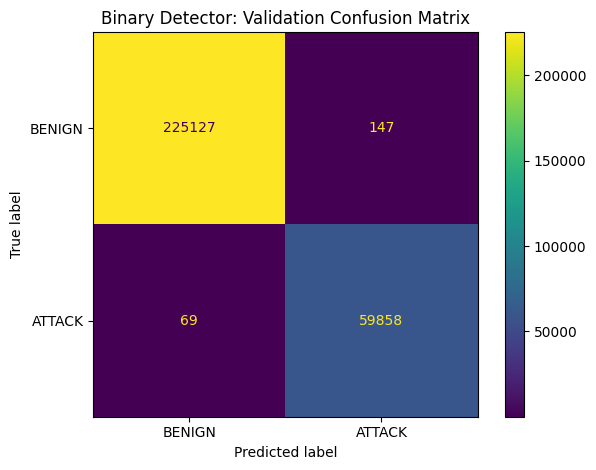

In [9]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    average_precision_score,
)
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Predictions using the best iteration selected during training.
y_val_prob = binary_model.predict_proba(
    X_val_imputed,
    iteration_range=(0, binary_model.best_iteration + 1)
)[:, 1]

y_val_pred = (y_val_prob >= 0.5).astype(np.uint8)

print("VALIDATION METRICS")
print("=" * 55)
print(f"Accuracy:          {accuracy_score(y_val, y_val_pred):.6f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_val, y_val_pred):.6f}")
print(f"Attack precision:  {precision_score(y_val, y_val_pred, zero_division=0):.6f}")
print(f"Attack recall:     {recall_score(y_val, y_val_pred, zero_division=0):.6f}")
print(f"Attack F1-score:   {f1_score(y_val, y_val_pred, zero_division=0):.6f}")
print(f"Average precision: {average_precision_score(y_val, y_val_prob):.6f}")

print("\nClassification report:")
print(
    classification_report(
        y_val,
        y_val_pred,
        labels=[0, 1],
        target_names=["BENIGN", "ATTACK"],
        digits=5,
        zero_division=0,
    )
)

cm = confusion_matrix(y_val, y_val_pred, labels=[0, 1])
print("Confusion matrix [BENIGN, ATTACK]:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "ATTACK"]
).plot(values_format="d")
plt.title("Binary Detector: Validation Confusion Matrix")
plt.tight_layout()
plt.show()


In [10]:

from pathlib import Path
import joblib
import json
from datetime import datetime, timezone

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")
MODEL_DIR = PROJECT_ROOT / "models" / "binary"
METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

BUNDLE_PATH = MODEL_DIR / "xgboost_binary_bundle.joblib"
METRICS_PATH = METRICS_DIR / "binary_validation_metrics.json"

# Save all preprocessing and inference requirements together.
bundle = {
    "model": binary_model,
    "imputer": imputer,
    "feature_columns": list(FEATURE_COLUMNS),
    "label_mapping": {
        "BENIGN": 0,
        "ATTACK": 1
    },
    "decision_threshold": 0.5,
    "best_iteration": int(binary_model.best_iteration),
    "validation_metrics": {
        "accuracy": float(accuracy_score(y_val, y_val_pred)),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_val, y_val_pred)
        ),
        "attack_precision": float(
            precision_score(y_val, y_val_pred, zero_division=0)
        ),
        "attack_recall": float(
            recall_score(y_val, y_val_pred, zero_division=0)
        ),
        "attack_f1": float(
            f1_score(y_val, y_val_pred, zero_division=0)
        ),
        "average_precision": float(
            average_precision_score(y_val, y_val_prob)
        ),
        "confusion_matrix": cm.tolist()
    },
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "xgboost_version": xgb.__version__
}

joblib.dump(bundle, BUNDLE_PATH, compress=3)

with open(METRICS_PATH, "w", encoding="utf-8") as f:
    json.dump(
        {
            "validation_metrics": bundle["validation_metrics"],
            "best_iteration": bundle["best_iteration"],
            "decision_threshold": bundle["decision_threshold"],
            "created_utc": bundle["created_utc"]
        },
        f,
        indent=2
    )

print("Binary model bundle saved:", BUNDLE_PATH)
print("Validation metrics saved:", METRICS_PATH)
print("Feature count:", len(bundle["feature_columns"]))
print("Best iteration:", bundle["best_iteration"])


Binary model bundle saved: /content/drive/MyDrive/H-IDS/models/binary/xgboost_binary_bundle.joblib
Validation metrics saved: /content/drive/MyDrive/H-IDS/outputs/metrics/binary_validation_metrics.json
Feature count: 78
Best iteration: 253


In [11]:

import joblib
import numpy as np
from pathlib import Path

BUNDLE_PATH = Path(
    "/content/drive/MyDrive/H-IDS/models/binary/"
    "xgboost_binary_bundle.joblib"
)

assert BUNDLE_PATH.exists(), "Model bundle not found."

loaded_bundle = joblib.load(BUNDLE_PATH)

loaded_model = loaded_bundle["model"]
loaded_imputer = loaded_bundle["imputer"]
loaded_features = loaded_bundle["feature_columns"]

assert len(loaded_features) == 78
assert hasattr(loaded_model, "predict_proba")
assert hasattr(loaded_imputer, "transform")

# Verify inference on a small sample from validation data.
sample = X_val.iloc[:10][loaded_features]
sample = sample.replace([np.inf, -np.inf], np.nan)

sample_imputed = loaded_imputer.transform(sample)
sample_predictions = loaded_model.predict_proba(
    sample_imputed,
    iteration_range=(0, loaded_bundle["best_iteration"] + 1)
)[:, 1]

print("Model reload: PASSED")
print("Feature count:", len(loaded_features))
print("Sample prediction probabilities:", sample_predictions)
print("All probabilities finite:", np.isfinite(sample_predictions).all())


Model reload: PASSED
Feature count: 78
Sample prediction probabilities: [2.9668124e-07 1.8698480e-06 8.0110614e-05 3.4220379e-06 7.0299097e-07
 1.2689396e-06 1.2428800e-05 2.7256021e-06 1.2335669e-04 4.6995467e-07]
All probabilities finite: True


FINAL BINARY TEST RESULTS
{
  "test_records": 555056,
  "accuracy": 0.9991892709924765,
  "balanced_accuracy": 0.9989713526344549,
  "attack_precision": 0.9970210461157536,
  "attack_recall": 0.998624377579292,
  "attack_f1": 0.9978220677772508,
  "average_precision": 0.9998679695157956,
  "confusion_matrix": [
    [
      451522,
      308
    ],
    [
      142,
      103084
    ]
  ],
  "decision_threshold": 0.5,
  "best_iteration": 253
}

Classification report:
              precision    recall  f1-score   support

      BENIGN    0.99969   0.99932   0.99950    451830
      ATTACK    0.99702   0.99862   0.99782    103226

    accuracy                        0.99919    555056
   macro avg    0.99835   0.99897   0.99866    555056
weighted avg    0.99919   0.99919   0.99919    555056



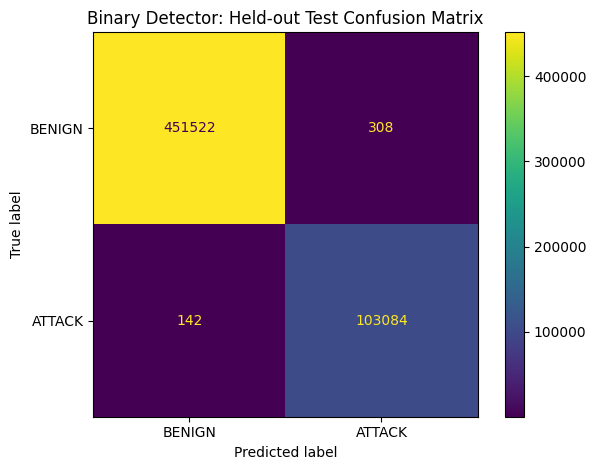


Test metrics saved to: /content/drive/MyDrive/H-IDS/outputs/metrics/binary_test_metrics.json


8482

In [12]:

import pandas as pd
import numpy as np
import joblib
import json
import gc

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")
TEST_PATH = PROJECT_ROOT / "data/splits/test.parquet"
BUNDLE_PATH = (
    PROJECT_ROOT / "models/binary/xgboost_binary_bundle.joblib"
)

# Load the saved model bundle.
bundle = joblib.load(BUNDLE_PATH)
model = bundle["model"]
imputer = bundle["imputer"]
features = bundle["feature_columns"]
best_iteration = bundle["best_iteration"]

# Load only the test features and labels.
test_df = pd.read_parquet(
    TEST_PATH,
    columns=features + ["label"]
)

X_test = test_df[features].replace(
    [np.inf, -np.inf], np.nan
).astype(np.float32)

y_test = (
    test_df["label"].astype(str) != "BENIGN"
).astype(np.uint8).to_numpy()

# Apply the training-fitted imputer.
X_test_imputed = imputer.transform(X_test).astype(np.float32)

assert X_test_imputed.shape == (555_056, 78)
assert len(y_test) == len(X_test_imputed)
assert np.isfinite(X_test_imputed).all()

# Predict at the best iteration selected on validation data.
y_test_prob = model.predict_proba(
    X_test_imputed,
    iteration_range=(0, best_iteration + 1)
)[:, 1]

y_test_pred = (y_test_prob >= 0.5).astype(np.uint8)

# Final held-out test metrics.
test_metrics = {
    "test_records": int(len(y_test)),
    "accuracy": float(accuracy_score(y_test, y_test_pred)),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_test, y_test_pred)
    ),
    "attack_precision": float(
        precision_score(y_test, y_test_pred, zero_division=0)
    ),
    "attack_recall": float(
        recall_score(y_test, y_test_pred, zero_division=0)
    ),
    "attack_f1": float(
        f1_score(y_test, y_test_pred, zero_division=0)
    ),
    "average_precision": float(
        average_precision_score(y_test, y_test_prob)
    ),
    "confusion_matrix": confusion_matrix(
        y_test, y_test_pred, labels=[0, 1]
    ).tolist(),
    "decision_threshold": 0.5,
    "best_iteration": int(best_iteration),
}

print("FINAL BINARY TEST RESULTS")
print("=" * 55)
print(json.dumps(test_metrics, indent=2))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["BENIGN", "ATTACK"],
    digits=5,
    zero_division=0,
))

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(
        y_test, y_test_pred, labels=[0, 1]
    ),
    display_labels=["BENIGN", "ATTACK"],
).plot(values_format="d")
plt.title("Binary Detector: Held-out Test Confusion Matrix")
plt.tight_layout()
plt.show()

# Save the final test metrics.
metrics_path = (
    PROJECT_ROOT / "outputs/metrics/binary_test_metrics.json"
)
metrics_path.parent.mkdir(parents=True, exist_ok=True)

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(test_metrics, f, indent=2)

print("\nTest metrics saved to:", metrics_path)

del test_df, X_test, X_test_imputed
gc.collect()
